# Bayesian Linear Regression: MCMC from Scratch and HMC/NUTS

This notebook studies a noisy 1-D regression problem with a Bayesian linear-in-the-parameters model, and uses it to compare two ways of doing posterior inference by sampling:

1. a **Metropolis** sampler implemented from scratch (NumPy / SciPy only), and
2. **Hamiltonian Monte Carlo with the No-U-Turn Sampler (NUTS)** from `numpyro`.

**Contents**

| Section | Topic |
|---|---|
| 1 | Hyperparameter posterior $p(\alpha, r \mid \mathbf{y})$ on a grid |
| 2 | Metropolis MCMC: implementation, proposal-scale experiments, adding $\sigma$, then sampling *all* unknowns (33-D) |
| 3 | HMC/NUTS in `numpyro`: model, diagnostics, and pragmatic vs fully Bayesian prediction |

Run from the `notebooks/` directory so that the helper module in `../src` is found.

## Problem set-up

The data are synthetic: generated from randomly weighted Gaussian basis functions with additive Gaussian noise of standard deviation $\sigma$. They are modelled with the standard Bayesian linear model

$$y = \sum_{m} w_m\,\phi_m(x; c_m, r) + \varepsilon, \qquad \mathbf{w} \sim \mathcal{N}(\mathbf{0}, \alpha^{-1}\mathbf{I}), \qquad \varepsilon \sim \mathcal{N}(0, \sigma^2),$$

with Gaussian RBF basis functions $\phi_m(x; c_m, r) = \exp\{-(x-c_m)^2/r^2\}$ of common width $r$.

The quantities of interest are the hyperparameters $\alpha$ (weight-prior precision), $r$ (basis width) and $\sigma$ (noise level), plus the resulting predictor.

## Setup

Imports and the shared helper module (`../src/bayes_utils.py`), which provides data generation, the RBF basis, the closed-form weight posterior and two implementations of the log marginal likelihood (`compute_log_marginal_scipy` and the cheaper `compute_log_marginal_woodbury`).

In [32]:
##
## Setup
##
# Standard modules
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance  # Needed for RBF

# Modules required for MCMC
import jax
import jax.numpy as jnp  # Use instead of numpy 'np' in numpyro model functions, e.g. RBF
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import arviz as az  # This may give a compatibility warning - this is OK!

# Shared helper module (data generation, RBF basis, marginal likelihood, plotting)
import sys
sys.path.insert(0, '../src')
import bayes_utils as setup

# Setup for Jax and numpyro
jax.config.update('jax_platforms', 'cpu')
# Uncomment if necessary (hopefully not) - otherwise, jax defaults to 32-bit
# jax.config.update("jax_enable_x64", True)

print(f"Using version {numpyro.__version__} of numpyro")

Using version 0.20.1 of numpyro


Fixed constants: data-set sizes and the generative noise standard deviation $\sigma = 0.2$ (assumed known at first, then estimated). Basis-function centres are fixed; only the width $r$ varies.

In [33]:
#
# Setup
#
# Define some fixed values
#
# Parameters that determine the generated data
#
sigma = 0.2  # Standard deviation of data observations
sigma_2 = sigma ** 2  # Variance
radius_gen = 1.00  # Generative basis radius or width
#
N_train = 30
N_test = 1000

### Generate data and basis

- **Training set:** $N=30$ points with noise $\sigma=0.20$.
- **Test set:** $N=1000$ noise-free points representing the true function.
- Inputs lie in $[0, 10]$.
- **Basis:** 29 equally spaced Gaussian RBFs plus a bias term (30 weights).

The cell below shows a deliberately sub-optimal fit (basis functions too narrow) and demonstrates how `RBFGenerator` is used.

N_train = 30
Empirical σ_train = 0.200
N_test = 1000


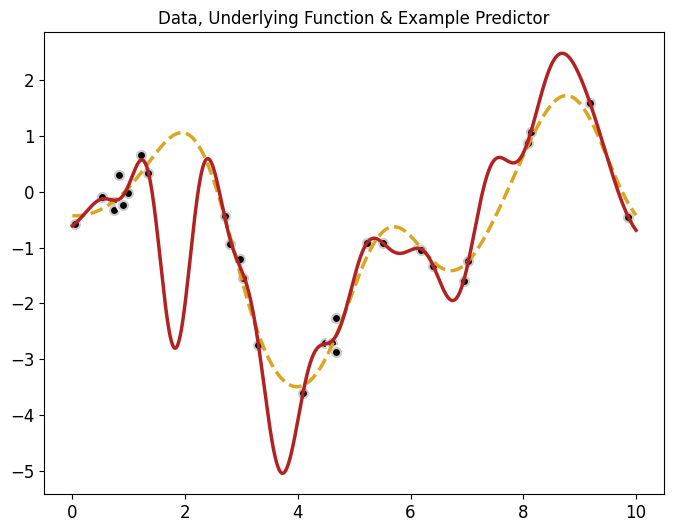

In [34]:
# Generate training data
generator = setup.DataGenerator(r=radius_gen, noise=sigma, seed=20)
x_train, y_train = generator.get_data('TRAIN', N_train)
x_test, y_test = generator.get_data('TEST', N_test)

# Demonstrate use of basis
centres = np.linspace(generator.x_min, generator.x_max, N_train - 1)
radius_model = radius_gen * 0.5  # Example model uses basis functions that are too narrow
RBF = setup.RBFGenerator(centres, radius_model, bias=True)
PHI_train = RBF.evaluate(x_train)
PHI_test = RBF.evaluate(x_test)

# Find quick fit for fixed guess for alpha and known s2
alph = 1e-4
w_pls = np.linalg.inv(PHI_train.T @ PHI_train + alph * np.eye(RBF.M)) @ PHI_train.T @ y_train
fy_test = PHI_test @ w_pls

# Show the training data and generating function, plus our mean fit
setup.plot_regression(x_train, y_train, x_test, y_test, fy_test)
plt.title("Data, Underlying Function & Example Predictor");

## Objective

The initial goal is a "good" value for the basis width $r$. Strictly, a Bayesian would integrate over $r$ when predicting, but in a deployed system there may be no budget for running samplers in real time. So we also take a pragmatic view: find a single good value of $r$ during model development, integrating out the other unknowns (the nuisance variables). Most of those integrals are intractable, hence the sampling methods below. Later sections *do* integrate over $r$ for the fully Bayesian predictor.

# 1. Computing and visualising the hyperparameter posterior

For now the noise variance $\sigma^2 = 0.2^2$ is treated as known (it is estimated in Section 2).

### 1a. The hyperparameter posterior

By Bayes' rule,

$$p(\alpha, r \mid \mathbf{y}) = \frac{p(\mathbf{y}\mid\alpha,r)\, p(\alpha)\, p(r)}{p(\mathbf{y})}.$$

The denominator is intractable, but the numerator $P^\ast(\alpha, r)$ is enough for visualisation and sampling. $\alpha$ and $r$ are scale parameters, so I place uninformative priors that are uniform on a **log scale**; those prior terms are then constant, and working in $\log\alpha$, $\log r$ gives

$$p(\alpha, r \mid \mathbf{y}) \propto p(\mathbf{y}\mid\alpha, r),$$

the marginal likelihood (with the weights integrated out analytically), which depends on $r$ through the basis matrix $\Phi$.

In [35]:
def log_prob_alph_r_given_y(alph, r, s2, x, y, centres):
    """
    Compute log p(alpha, r | y) up to a constant.
    With uniform log-priors on alpha and r, this equals log p(y | alpha, r).
    """
    RBF = setup.RBFGenerator(centres, width=r, bias=True)
    PHI = RBF.evaluate(x)
    log_ml = setup.compute_log_marginal_woodbury(PHI, y, alph, s2)
    return log_ml

### 1b. Visualise the posterior and locate its maximum

$p(\mathbf{y}\mid\alpha, r)$ is evaluated on a regular logarithmic grid, with $\log_{10}\alpha \in [-6, 4]$ and $\log_{10} r \in [-2, 1]$ (100 steps each; decimal logs for parameter values, natural logs for probabilities). The log-posterior is far more informative than the posterior itself, which is sharply localised, so both are shown.

In [36]:
# Calculate p(alpha,r|y) and log p(alpha,r|y) for visualisation.

log10_alpha_lims = [-6, +4]
log10_r_lims = [-2, +1]

N_grid = 100
log10_alpha_range = np.linspace(log10_alpha_lims[0], log10_alpha_lims[1], N_grid)
log10_r_range = np.linspace(log10_r_lims[0], log10_r_lims[1], N_grid)

log_posterior = np.empty((N_grid, N_grid))

for i, log10_r_val in enumerate(log10_r_range):
    for j, log10_a_val in enumerate(log10_alpha_range):
        alph_val = 10 ** log10_a_val
        r_val = 10 ** log10_r_val
        try:
            log_posterior[i, j] = log_prob_alph_r_given_y(
                alph_val, r_val, sigma_2, x_train, y_train, centres)
        except np.linalg.LinAlgError:
            log_posterior[i, j] = -np.inf

# Exponentiate for p(alpha, r | y) - subtract max for numerical stability
log_posterior_shifted = log_posterior - np.nanmax(log_posterior)
posterior = np.exp(log_posterior_shifted)

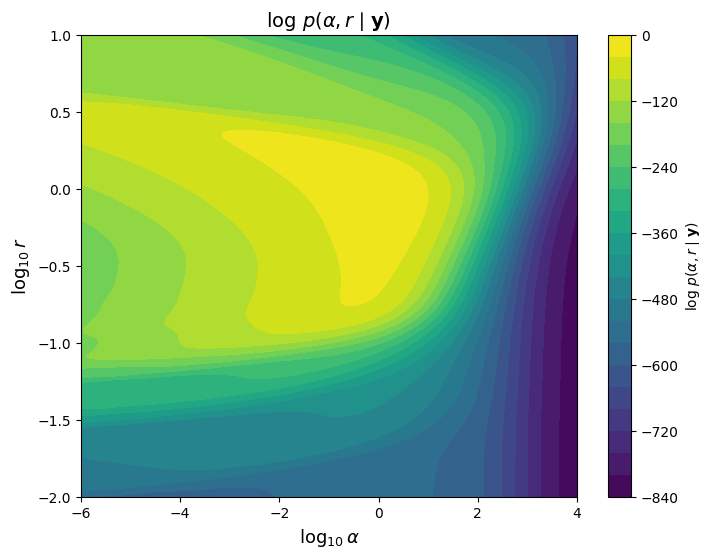

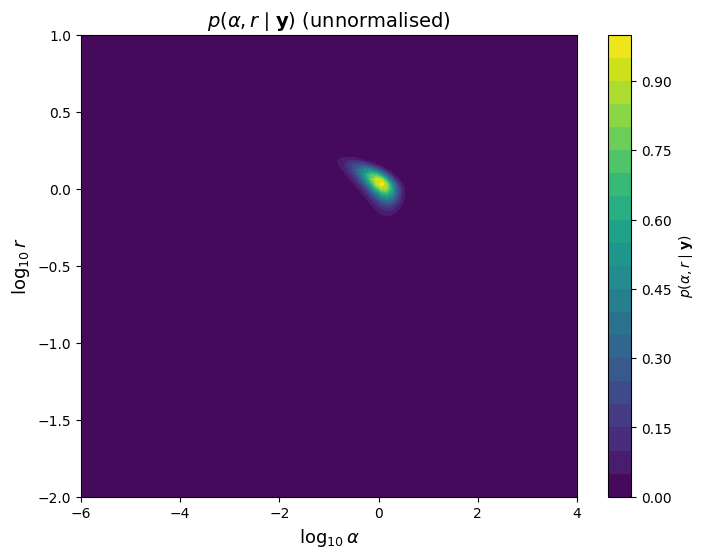

In [37]:
#
# Figure 1: log p(alpha, r | y)
plt.figure(figsize=(8, 6))
plt.contourf(log10_alpha_range, log10_r_range, log_posterior, levels=20, cmap='viridis')
plt.colorbar(label=r'$\log\, p(\alpha, r \mid \mathbf{y})$')
plt.xlabel(r'$\log_{10} \alpha$', fontsize=13)
plt.ylabel(r'$\log_{10} r$', fontsize=13)
plt.title(r'$\log\, p(\alpha, r \mid \mathbf{y})$', fontsize=14)
plt.show()

# Figure 2: p(alpha, r | y)
plt.figure(figsize=(8, 6))
plt.contourf(log10_alpha_range, log10_r_range, posterior, levels=20, cmap='viridis')
plt.colorbar(label=r'$p(\alpha, r \mid \mathbf{y})$')
plt.xlabel(r'$\log_{10} \alpha$', fontsize=13)
plt.ylabel(r'$\log_{10} r$', fontsize=13)
plt.title(r'$p(\alpha, r \mid \mathbf{y})$ (unnormalised)', fontsize=14)
plt.show()

In [38]:
# Report the maximum of log p(alpha, r | y) and the corresponding parameter values
idx_max = np.unravel_index(np.argmax(log_posterior), log_posterior.shape)
best_log10_r = log10_r_range[idx_max[0]]
best_log10_alpha = log10_alpha_range[idx_max[1]]
best_log_prob = log_posterior[idx_max]

table = [
    ["max log p(α, r | y)", f"{best_log_prob:.4f}"],
    ["log₁₀ α (most probable)", f"{best_log10_alpha:.4f}"],
    ["log₁₀ r (most probable)", f"{best_log10_r:.4f}"],
    ["α (most probable)", f"{10**best_log10_alpha:.6f}"],
    ["r (most probable)", f"{10**best_log10_r:.6f}"],
]
setup.tabulate_neatly(table, headers=["Quantity", "Value"],
                      title="Hyperparameter Posterior Maximum")

Hyperparameter Posterior Maximum

Quantity,Value
"max log p(α, r | y)",-20.6735
log₁₀ α (most probable),0.0606
log₁₀ r (most probable),0.0303
α (most probable),1.14976
r (most probable),1.07227


### Reproducibility

Random seeds are fixed (via `np.random.seed`) before each sampling experiment so that results can be reproduced.

# 2. MCMC and the Metropolis algorithm

Implement the Metropolis sampler, use it to estimate $\langle r \rangle$, extend it to estimate $\sigma$, and finally sample *all* the model unknowns.

### 2a. The Metropolis sampler

```python
samples, rejected = metropolis(num_samples, pstar, qrvs, x0)
```

- `pstar(x)` returns the unnormalised target $P^\ast(x)$, e.g. for `x = [log_alpha, log_r]`.
- `qrvs(x)` draws a proposal $x'$ from the symmetric proposal $Q(x' \mid x)$.
- `x0` is the starting state (included as the first sample).
- When a proposal is rejected, the current state is **repeated** in the output chain; rejected proposals are returned separately for plotting.

In [39]:
# Metropolis algorithm implementation

from scipy import stats

def metropolis(num_samples, pstar, qrvs, x0):
    """
    Metropolis MCMC sampler.

    Parameters
    num_samples : int - Number of samples desired
    pstar : callable - Returns P*(x), the unnormalised target density
    qrvs : callable - Takes current state x, returns proposal x'
    x0 : np.ndarray - Starting state (included as first sample)

    Returns
    samples : np.ndarray of shape (num_samples+1, D)
    rejected : np.ndarray of all rejected proposals
    """
    D = len(x0)
    samples = np.zeros((num_samples + 1, D))
    samples[0] = x0
    rejected_list = []
    pstar_current = pstar(x0)

    for t in range(num_samples):
        # Generate proposal from Q(x'|x)
        x_proposal = qrvs(samples[t])
        # Evaluate P*(x')
        pstar_proposal = pstar(x_proposal)
        # Acceptance ratio (symmetric Q, so Q terms cancel)
        if pstar_current > 0:
            kappa = pstar_proposal / pstar_current
        else:
            kappa = 1.0 if pstar_proposal > 0 else 0.0
        # Accept or reject
        if kappa >= 1 or np.random.uniform() < kappa:
            samples[t + 1] = x_proposal
            pstar_current = pstar_proposal
        else:
            samples[t + 1] = samples[t]
            rejected_list.append(x_proposal)

    rejected = np.array(rejected_list) if rejected_list else np.empty((0, D))
    return samples, rejected

### 2b. Estimating $\langle r \rangle$ with three proposal scales

$\langle r \rangle$ is computed under $p(\alpha, r \mid \mathbf{y})$ (with $\sigma^2$ known) using an isotropic Gaussian proposal $Q$ at three length scales:

1. **too narrow:** very high acceptance rate (> 80%), and the chain random-walks;
2. **too broad:** very low acceptance rate;
3. **"just right":** acceptance in the 20-30% region (theory suggests about 23% is near ideal).

For each scale the notebook reports the acceptance rate and final $\langle r \rangle$, overlays accepted and rejected samples on the posterior contours (starting deliberately away from the maximum so the burn-in is visible), and plots the running estimate of $\langle r \rangle$ together with a histogram/KDE of the post-burn-in samples (first 10% discarded).

In [40]:
# Section 2b

import seaborn as sns

seed = 42
np.random.seed(seed)
num_samples = 10000
burn_in_frac = 0.10

def pstar_alph_r(x):
    """x = [log10_alpha, log10_r], sigma^2 known"""
    log10_a, log10_r = x
    alph = 10 ** log10_a
    r = 10 ** log10_r
    try:
        log_val = log_prob_alph_r_given_y(alph, r, sigma_2, x_train, y_train, centres)
        return np.exp(log_val)
    except (np.linalg.LinAlgError, ValueError):
        return 0.0

proposal_scales = {
    'too narrow': 0.02,
    'too broad': 3.0,
    'just right': 0.2,
}

# Start deliberately away from the maximum so the burn-in is visible
x0 = np.array([-3.0, -1.0])

results_table = []
all_runs = {}

for label, scale in proposal_scales.items():
    np.random.seed(seed)
    def qrvs(x, s=scale):
        return x + np.random.normal(0, s, size=len(x))

    samples, rejected = metropolis(num_samples, pstar_alph_r, qrvs, x0)
    acc_rate = (num_samples - len(rejected)) / num_samples
    burn_in = int(burn_in_frac * num_samples)
    samples_post_burn = samples[burn_in:]
    r_samples = 10 ** samples_post_burn[:, 1]
    mean_r = np.mean(r_samples)

    results_table.append([label, scale, f"{acc_rate:.3f}", f"{mean_r:.4f}"])
    all_runs[label] = {
        'samples': samples, 'rejected': rejected,
        'acc_rate': acc_rate, 'mean_r': mean_r, 'scale': scale,
    }

setup.tabulate_neatly(
    results_table,
    headers=["Proposal", "Scale", "Acceptance Rate", "⟨r⟩"],
    title="Metropolis Sampling Results"
)

Metropolis Sampling Results

Proposal,Scale,Acceptance Rate,⟨r⟩
too narrow,0.02,0.87,1.0807
too broad,3,0.004,1.0668
just right,0.2,0.274,1.092


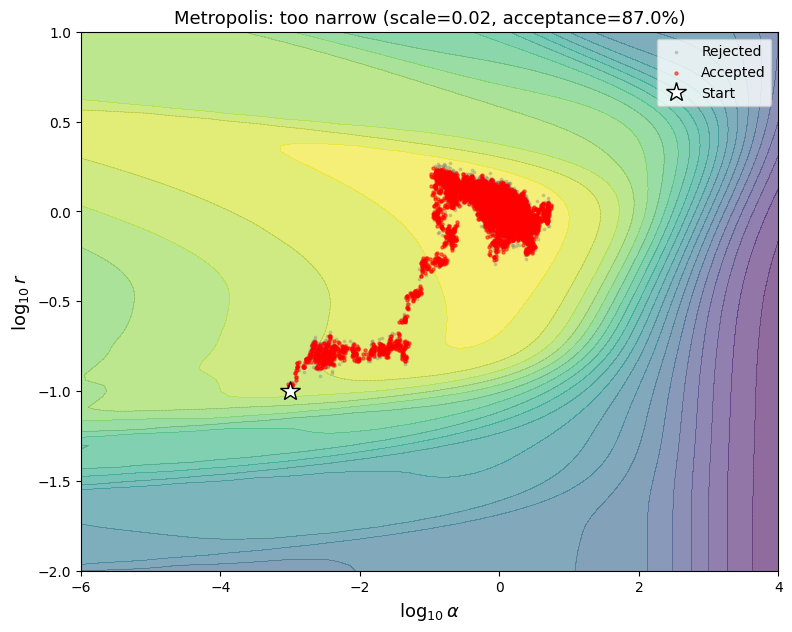

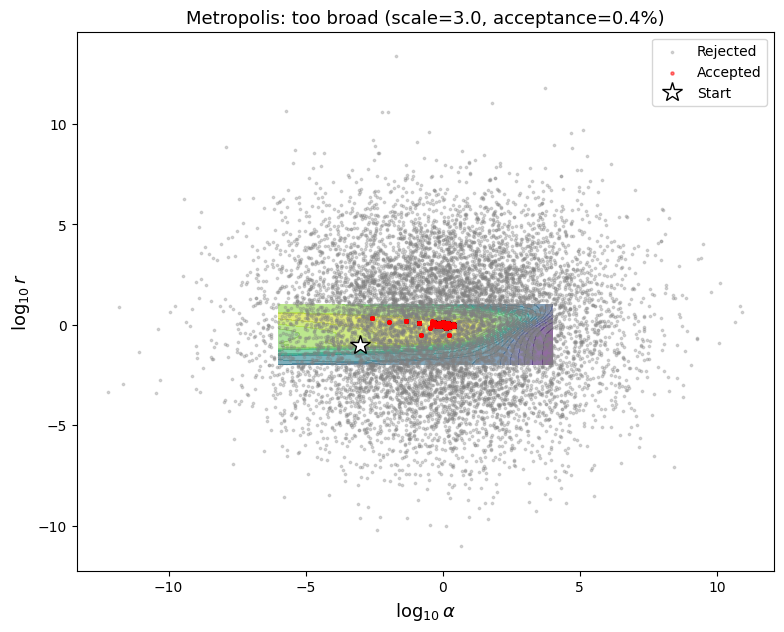

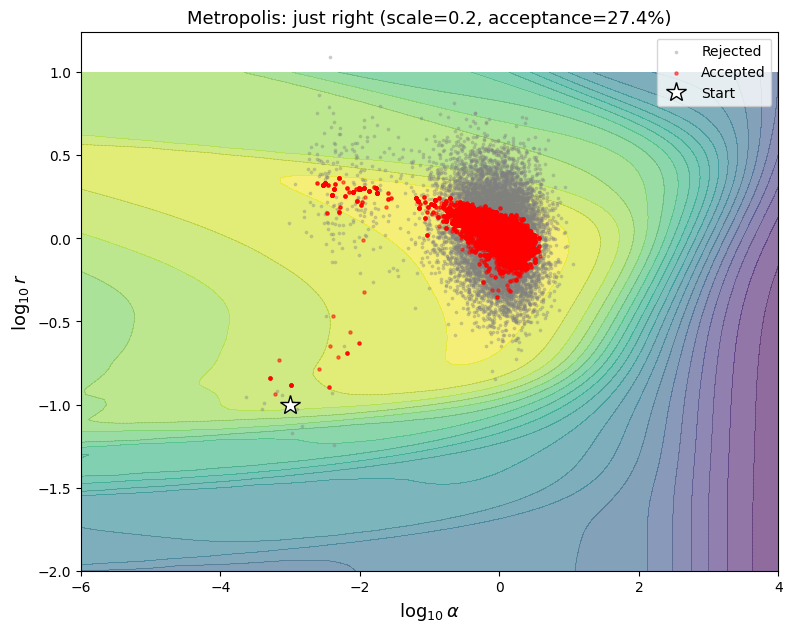

In [41]:
# Visualise accepted / rejected samples on the posterior contours
burn_in = int(burn_in_frac * num_samples)

for label, run in all_runs.items():
    samples = run['samples']
    rejected = run['rejected']
    acc_rate = run['acc_rate']

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.contourf(log10_alpha_range, log10_r_range, log_posterior,
                levels=20, cmap='viridis', alpha=0.6)
    ax.contour(log10_alpha_range, log10_r_range, log_posterior,
               levels=10, colors='grey', alpha=0.4, linewidths=0.5)
    if len(rejected) > 0:
        ax.scatter(rejected[:, 0], rejected[:, 1], c='grey', s=3, alpha=0.3,
                   label='Rejected')
    ax.scatter(samples[:, 0], samples[:, 1], c='red', s=5, alpha=0.5,
               label='Accepted')
    ax.plot(samples[0, 0], samples[0, 1], 'w*', ms=15, markeredgecolor='black',
            label='Start')
    ax.set_xlabel(r'$\log_{10} \alpha$', fontsize=13)
    ax.set_ylabel(r'$\log_{10} r$', fontsize=13)
    ax.set_title(f'Metropolis: {label} (scale={run["scale"]}, '
                 f'acceptance={acc_rate:.1%})', fontsize=13)
    ax.legend(fontsize=10)
    plt.show()

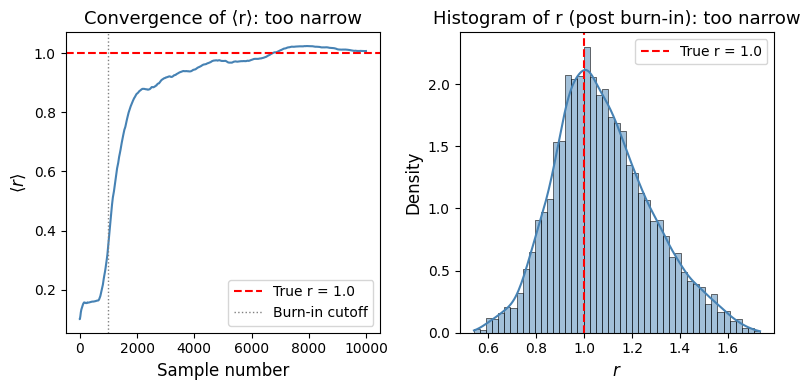

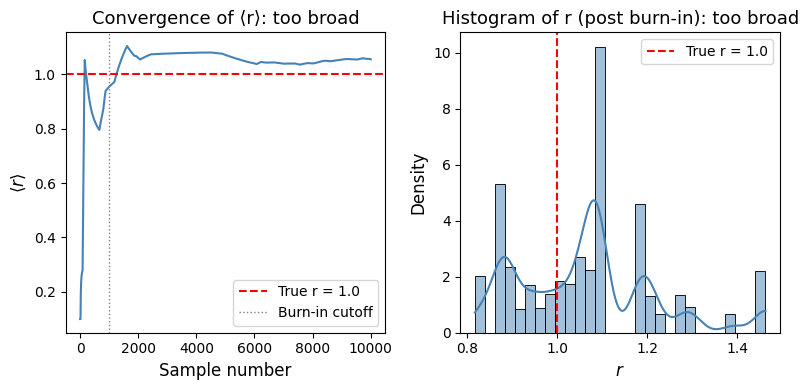

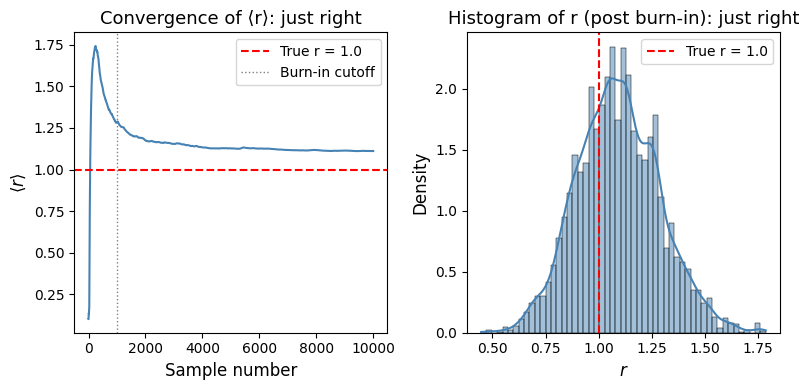

In [42]:
# Diagnostics: running <r> and histogram of post-burn-in samples
for label, run in all_runs.items():
    samples = run['samples']
    burn_in = int(burn_in_frac * num_samples)
    log10_r_samples = samples[:, 1]
    r_samples_all = 10 ** log10_r_samples
    cumulative_mean_r = np.cumsum(r_samples_all) / np.arange(1, len(r_samples_all) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(8,4))

    # Convergence of <r>
    axes[0].plot(cumulative_mean_r, color='steelblue', lw=1.5)
    axes[0].axhline(y=radius_gen, color='red', ls='--', lw=1.5, label=f'True r = {radius_gen}')
    axes[0].axvline(x=burn_in, color='grey', ls=':', lw=1, label='Burn-in cutoff')
    axes[0].set_xlabel('Sample number', fontsize=12)
    axes[0].set_ylabel(r'$\langle r \rangle$', fontsize=12)
    axes[0].set_title(f'Convergence of ⟨r⟩: {label}', fontsize=13)
    axes[0].legend()

    # Histogram with KDE (post burn-in)
    r_post_burn = r_samples_all[burn_in:]
    sns.histplot(r_post_burn, kde=True, stat='density', ax=axes[1], color='steelblue')
    axes[1].axvline(x=radius_gen, color='red', ls='--', lw=1.5, label=f'True r = {radius_gen}')
    axes[1].set_xlabel(r'$r$', fontsize=12)
    axes[1].set_ylabel('Density', fontsize=12)
    axes[1].set_title(f'Histogram of r (post burn-in): {label}', fontsize=13)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

### 2c. Adding the noise level $\sigma$

The sampler is extended to a third dimension, $\log_{10}\sigma$ (again with a uniform log prior), using a single "just right" proposal scale. Diagnostics: the running estimate of $\langle\sigma\rangle$ and a histogram/KDE of post-burn-in samples.

Acceptance rate (3D): 0.227


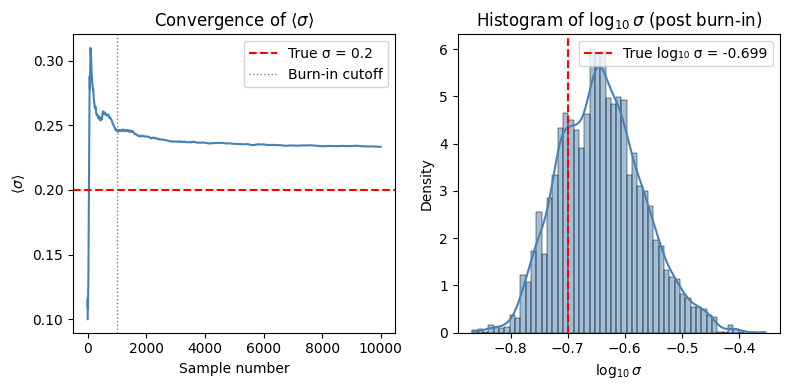


Final estimate: ⟨σ⟩ = 0.2319 (true value: 0.2)


In [43]:
# Section 2c

# Extend the Metropolis sampler to estimate the noise std dev

np.random.seed(seed)

def pstar_alph_r_sigma(x):
    """x = [log10_alpha, log10_r, log10_sigma]"""
    log10_a, log10_r, log10_s = x
    alph = 10 ** log10_a
    r = 10 ** log10_r
    s2 = (10 ** log10_s) ** 2
    try:
        log_val = log_prob_alph_r_given_y(alph, r, s2, x_train, y_train, centres)
        return np.exp(log_val)
    except (np.linalg.LinAlgError, ValueError):
        return 0.0

scale_3d = 0.15
def qrvs_3d(x):
    return x + np.random.normal(0, scale_3d, size=len(x))

x0_3d = np.array([-3.0, -1.0, -1.0])
samples_3d, rejected_3d = metropolis(num_samples, pstar_alph_r_sigma, qrvs_3d, x0_3d)

acc_rate_3d = (num_samples - len(rejected_3d)) / num_samples
print(f"Acceptance rate (3D): {acc_rate_3d:.3f}")

burn_in_3d = int(burn_in_frac * num_samples)
sigma_samples = 10 ** samples_3d[burn_in_3d:, 2]
sigma_all = 10 ** samples_3d[:, 2]
cum_mean_sigma = np.cumsum(sigma_all) / np.arange(1, len(sigma_all) + 1)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].plot(cum_mean_sigma, color='steelblue', lw=1.5)
axes[0].axhline(y=sigma, color='red', ls='--', lw=1.5, label=f'True σ = {sigma}')
axes[0].axvline(x=burn_in_3d, color='grey', ls=':', lw=1, label='Burn-in cutoff')
axes[0].set_xlabel('Sample number'); axes[0].set_ylabel(r'$\langle \sigma \rangle$')
axes[0].set_title(r'Convergence of $\langle \sigma \rangle$'); axes[0].legend()

log10_sigma_post = samples_3d[burn_in_3d:, 2]
sns.histplot(log10_sigma_post, kde=True, stat='density', ax=axes[1], color='steelblue')
axes[1].axvline(x=np.log10(sigma), color='red', ls='--', lw=1.5,
                label=f'True log₁₀ σ = {np.log10(sigma):.3f}')
axes[1].set_xlabel(r'$\log_{10} \sigma$'); axes[1].set_ylabel('Density')
axes[1].set_title(r'Histogram of $\log_{10} \sigma$ (post burn-in)'); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"\nFinal estimate: ⟨σ⟩ = {np.mean(sigma_samples):.4f} (true value: {sigma})")

### 2d. Sampling *all* the unknowns (33-D)

Here the weights are sampled too, giving a 33-dimensional state: 30 weights plus $\alpha$, $r$ and $\sigma$. This is slightly artificial for this model, whose weight posterior is available in closed form, but it shows the principle needed for models that are *non*-linear in $\mathbf{w}$ (e.g. neural networks).

The target is

$$P^\ast(\mathbf{w}, \alpha, r, \sigma^2) = p(\mathbf{y}\mid\mathbf{w}, r, \sigma^2)\, p(\mathbf{w}\mid\alpha),$$

(the log-uniform hyperpriors are constant), and the quantity of interest is the posterior-mean predictor

$$\langle \mathbf{y}_\ast \rangle = \int (\Phi_\ast \mathbf{w})\; p(\mathbf{w}, \alpha, r, \sigma^2 \mid \mathbf{y})\; d\mathbf{w}\, d\alpha\, dr\, d\sigma^2 ,$$

with $\Phi_\ast$ the basis matrix at the test inputs (it depends on $r$). Separate proposal scales are used for the weights and for the hyperparameters, aiming for roughly 25% acceptance. As a sanity check, $\langle\sigma\rangle$ from the same samples should be close to the true 0.2.

In [44]:
# Section 2d

# Extend the Metropolis sampler to model all unknowns and plot a mean predictor

np.random.seed(seed)
M = len(centres) + 1

def new_log_pstar(x):
    """x = [w_0,...,w_{M-1}, log10_alpha, log10_r, log10_sigma] (33-dim)"""
    w = x[:M].reshape(-1, 1)
    alph = 10 ** x[M]
    r = 10 ** x[M + 1]
    s2 = (10 ** x[M + 2]) ** 2
    beta = 1.0 / s2

    RBF = setup.RBFGenerator(centres, width=r, bias=True)
    PHI = RBF.evaluate(x_train)
    N = len(y_train)

    residuals = y_train - PHI @ w
    log_lik = -0.5 * N * np.log(2 * np.pi * s2) - 0.5 * beta * (residuals.T @ residuals).item()
    log_prior_w = -0.5 * M * np.log(2 * np.pi / alph) - 0.5 * alph * (w.T @ w).item()
    return log_lik + log_prior_w

def pstar_full(x):
    log_val = new_log_pstar(x)
    if log_val > 500: return np.exp(500)
    return np.exp(log_val) if log_val > -700 else 0.0

scale_w = 0.006
scale_hp = 0.06

def qrvs_full(x):
    proposal = x.copy()
    proposal[:M] += np.random.normal(0, scale_w, size=M)
    proposal[M:] += np.random.normal(0, scale_hp, size=3)
    return proposal

# Initialise weights at the posterior mean for the MAP hyperparameters
best_r = 10 ** best_log10_r
best_alpha = 10 ** best_log10_alpha
RBF_init = setup.RBFGenerator(centres, width=best_r, bias=True)
PHI_init = RBF_init.evaluate(x_train)
Mu_init, _ = setup.compute_posterior(PHI_init, y_train, best_alpha, sigma_2)

x0_full = np.zeros(M + 3)
x0_full[:M] = Mu_init.ravel()           # Start weights at posterior mean
x0_full[M] = best_log10_alpha
x0_full[M + 1] = best_log10_r
x0_full[M + 2] = np.log10(sigma)

num_samples_full = 10000
samples_full, rejected_full = metropolis(num_samples_full, pstar_full, qrvs_full, x0_full)
acc_rate_full = (num_samples_full - len(rejected_full)) / num_samples_full
print(f"Acceptance rate (full 33D): {acc_rate_full:.3f}")

Acceptance rate (full 33D): 0.216


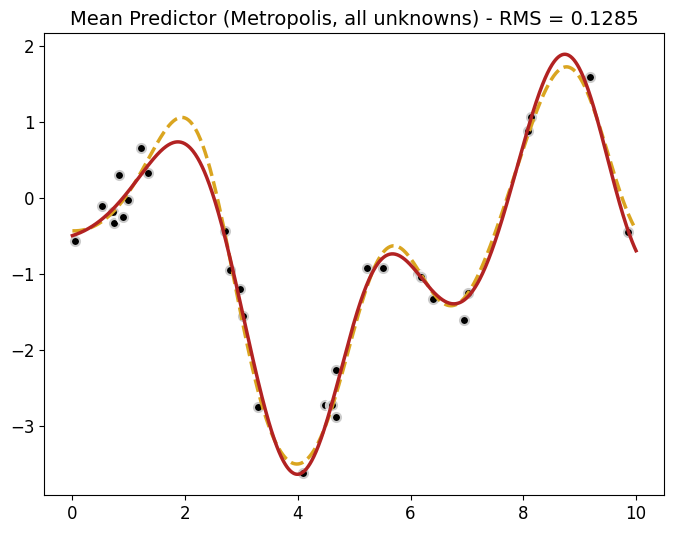

Estimated ⟨σ⟩ = 0.2088 (true value: 0.2)


In [45]:
# Mean predictor and noise estimate
burn_in_full = int(0.10 * num_samples_full)
samples_post = samples_full[burn_in_full:]

y_predictions = np.zeros((len(samples_post), len(x_test)))
for idx, sample in enumerate(samples_post):
    w_s = sample[:M].reshape(-1, 1)
    r_s = 10 ** sample[M + 1]
    RBF_s = setup.RBFGenerator(centres, width=r_s, bias=True)
    PHI_test_s = RBF_s.evaluate(x_test)
    y_predictions[idx] = (PHI_test_s @ w_s).ravel()

y_mean_pred = np.mean(y_predictions, axis=0).reshape(-1, 1)
sigma_est = np.mean(10 ** samples_post[:, M + 2])
rms_err = setup.error_rms(y_test, y_mean_pred)

setup.plot_regression(x_train, y_train, x_test, y_test, y_mean_pred,
                      title=f"Mean Predictor (Metropolis, all unknowns) - RMS = {rms_err:.4f}")
plt.show()
print(f"Estimated ⟨σ⟩ = {sigma_est:.4f} (true value: {sigma})")

# 3. HMC with NUTS (`numpyro`)

The same problem, data and model, now using an off-the-shelf Hamiltonian Monte Carlo sampler with the No-U-Turn criterion. The steps are:

- write the model as a probabilistic program,
- run NUTS to sample all unknowns,
- tabulate posterior estimates for $\alpha$, $\sigma$, $r$,
- assess sampler performance with `arviz`,
- build predictors from the samples.

**Why bother?** Metropolis needed hand-tuning of proposal scales and burn-in, and its samples are correlated. NUTS adapts its step size and trajectory length during a warm-up phase, so those choices are largely automated. What remains for the analyst is mainly the choice of priors and parameterisation.

### JAX-compatible basis

`numpyro` needs a `jax`-compatible basis object. `JRBFGenerator` below differs from `RBFGenerator` in two ways: calls go to `jax.numpy`, and the radius is an argument of `evaluate` rather than an attribute, which makes it easy to vary $r$ inside the model.

In [46]:
#
# Basis class that is JAX compatible
# Centres are fixed for evaluation, but radius is parameterised
#
class JRBFGenerator(object):
    """Generate Jax-compatible Gaussian RBF basis
    with parameterised radius"""

    def __init__(self, loci, bias=False):
        self.M = len(loci)
        self.centres = loci.reshape((self.M, 1))
        self.is_bias = bias
        if bias:
            self.M += 1

    def evaluate(self, X, radius):
        N = len(X)
        d2 = distance.cdist(X, self.centres, metric="sqeuclidean")
        JPHI = jnp.exp(-d2 / (radius ** 2))
        if self.is_bias:
            JPHI = jnp.hstack((np.ones((N, 1)), JPHI))
        #
        return JPHI

### 3a. The model as a probabilistic program

`model(x, y)` declares each unknown with `numpyro.sample`:

- hyperpriors uniform on a log scale for $\log_{10}\alpha$, $\log_{10}\sigma$, $\log_{10} r$ (consistent with the earlier sections),
- weights $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \alpha^{-1}\mathbf{I})$,
- Gaussian observation model with `obs=y`.

In [47]:
# This can be defined just the once
JRBF = JRBFGenerator(centres, bias=True)

def model(x, y):
    log_alpha = numpyro.sample("log_alpha", dist.Uniform(-6, 4))
    log_sigma = numpyro.sample("log_sigma", dist.Uniform(-3, 1))
    log_r = numpyro.sample("log_r", dist.Uniform(-2, 1))

    alpha = numpyro.deterministic("alpha", 10.0 ** log_alpha)
    sigma_obs = numpyro.deterministic("sigma", 10.0 ** log_sigma)
    r = numpyro.deterministic("r", 10.0 ** log_r)

    w = numpyro.sample("w", dist.Normal(jnp.zeros(JRBF.M), jnp.sqrt(1.0 / alpha)).to_event(1))

    PHI = JRBF.evaluate(x.reshape(-1, 1), r)
    mu = PHI @ w
    numpyro.sample("obs", dist.Normal(mu, sigma_obs), obs=y)

### 3b. Visualise the model structure (optional)

`numpyro.render_model` draws the probabilistic graphical model. It needs the `graphviz` Python package **and** the system executables (e.g. `sudo apt install graphviz`); the cell fails gracefully if they are missing.

In [48]:
try:
    numpyro.render_model(model, model_args=(x_train.ravel(), y_train.ravel()),
                         render_distributions=True)
except Exception as e:
    print(f"Model rendering not available: {e}")

### 3c. Run the NUTS sampler

500 warm-up iterations followed by 1,000 samples, then the built-in summary. A healthy run shows no divergences and $\hat{R} \approx 1.00$ for every variable. The effective sample size is lower for the more "indirect" quantities ($\alpha$ and $r$).

In [49]:
num_warmup = 500
num_samples = 1000

kernel = NUTS(model)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples)
rng_key = jax.random.PRNGKey(0)
mcmc.run(rng_key, x_train.ravel(), y_train.ravel())
mcmc.print_summary()

sample: 100%|██████████| 1500/1500 [00:10<00:00, 139.00it/s, 127 steps of size 3.82e-02. acc. prob=0.91]


                 mean       std    median      5.0%     95.0%     n_eff     r_hat
  log_alpha     -0.01      0.27      0.03     -0.41      0.40     98.29      1.01
      log_r      0.02      0.08      0.03     -0.11      0.15    169.75      1.00
  log_sigma     -0.64      0.07     -0.65     -0.76     -0.53    632.41      1.00
       w[0]     -0.71      0.71     -0.67     -1.94      0.38    389.40      1.00
       w[1]      0.05      0.78      0.01     -1.22      1.19    448.87      1.00
       w[2]      0.06      0.94      0.02     -1.36      1.61   1032.83      1.00
       w[3]     -0.01      0.92     -0.00     -1.51      1.34   1186.50      1.00
       w[4]      0.03      0.89      0.09     -1.31      1.48   1048.90      1.00
       w[5]      0.15      0.96      0.20     -1.13      1.73    652.34      1.00
       w[6]      0.50      1.03      0.47     -0.87      2.36    581.25      1.00
       w[7]      0.64      0.97      0.61     -1.01      2.02   1176.59      1.00
       w[8]    

### 3d. Posterior estimates

Posterior means of $\log_{10}\alpha$, $\log_{10}\sigma$, $\log_{10} r$, their transformed values, and the true generative values for $\sigma$ and $r$.

In [50]:
posterior_samples = mcmc.get_samples()

mean_log_alpha = float(jnp.mean(posterior_samples["log_alpha"]))
mean_log_sigma = float(jnp.mean(posterior_samples["log_sigma"]))
mean_log_r = float(jnp.mean(posterior_samples["log_r"]))

table_3d = [
    ["α", f"{mean_log_alpha:.4f}", f"{10**mean_log_alpha:.6f}", "-"],
    ["σ", f"{mean_log_sigma:.4f}", f"{10**mean_log_sigma:.6f}", f"{sigma}"],
    ["r", f"{mean_log_r:.4f}", f"{10**mean_log_r:.6f}", f"{radius_gen}"],
]
setup.tabulate_neatly(table_3d,
    headers=["Parameter", " Mean log₁₀ value ", " 10^(mean log₁₀) ", " True value "],
    title="Posterior Mean Estimates (HMC/NUTS)")

Posterior Mean Estimates (HMC/NUTS)

Parameter,Mean log₁₀ value,10^(mean log₁₀),True value
α,-0.0074,0.982994,-
σ,-0.6417,0.228185,0.2
r,0.0198,1.04664,1.0


### 3e. Sampler diagnostics

`arviz` trace plots (KDE on the left, trace on the right; the 30 weights are overlaid with `compact=True`). Warning signs would be non-Gaussian weight marginals, multi-modal or heavily skewed hyperparameter marginals, or traces that show structure rather than looking like noise.

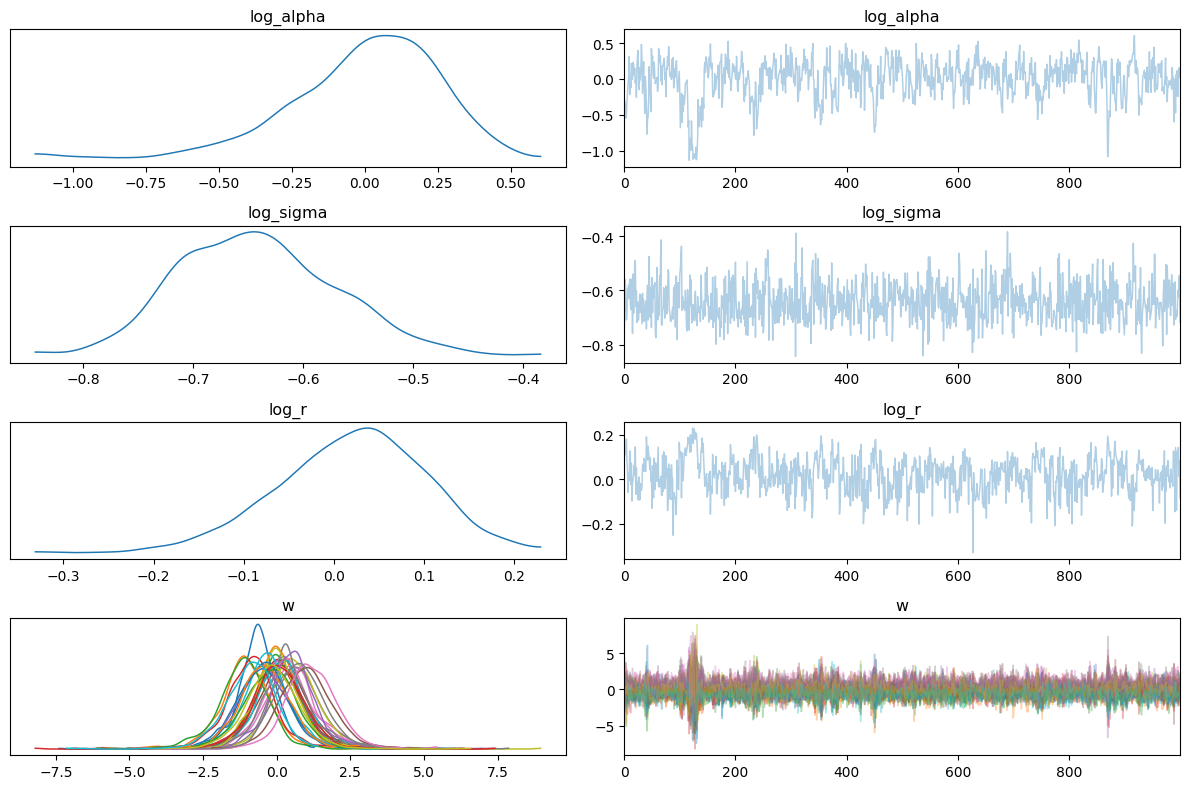

In [51]:
az_data = az.from_numpyro(mcmc)
az.plot_trace(az_data, var_names=["log_alpha", "log_sigma", "log_r", "w"], compact=True)
plt.tight_layout()
plt.show()

### 3f. Prediction

Two predictors are built from the NUTS samples and compared by RMS error against the true function on the test set:

1. **Pragmatic:** plug in a single value of $r$ (from the posterior mean of $\log r$) and the posterior-mean weights. Cheap enough to deploy.
2. **Fully Bayesian:** average the prediction $\Phi_\ast(r^{(s)})\,\mathbf{w}^{(s)}$ over all posterior samples, integrating over $r$ properly.

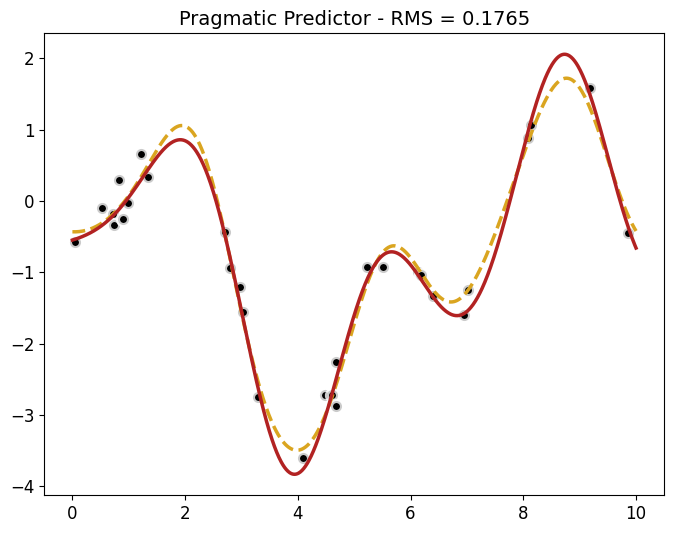

Pragmatic predictor RMS error: 0.1765


In [52]:
# Pragmatic predictions
mean_r = float(10 ** jnp.mean(posterior_samples["log_r"]))
mean_w = jnp.mean(posterior_samples["w"], axis=0)

JRBF_pred = JRBFGenerator(centres, bias=True)
PHI_test_prag = JRBF_pred.evaluate(x_test, mean_r)
y_pragmatic = np.array(PHI_test_prag @ mean_w).reshape(-1, 1)
rms_pragmatic = setup.error_rms(y_test, y_pragmatic)

setup.plot_regression(x_train, y_train, x_test, y_test, y_pragmatic,
                      title=f"Pragmatic Predictor - RMS = {rms_pragmatic:.4f}")
plt.show()
print(f"Pragmatic predictor RMS error: {rms_pragmatic:.4f}")

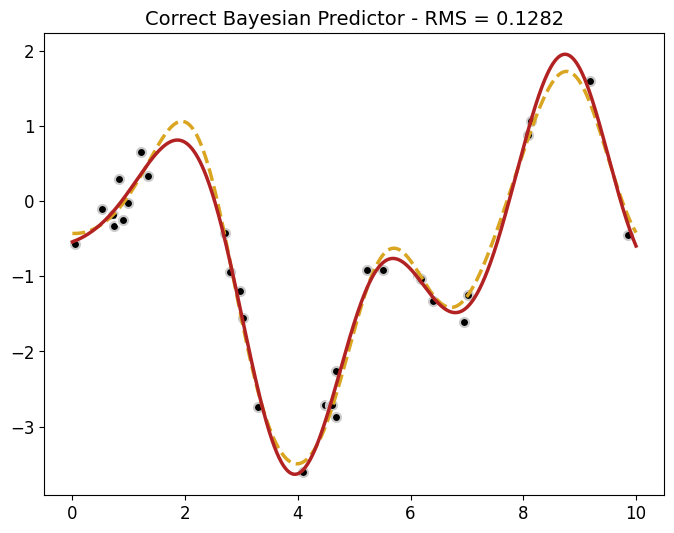

Bayesian predictor RMS error: 0.1282

Comparison: Pragmatic = 0.1765, Bayesian = 0.1282


In [53]:
# Bayesian predictions
r_samples_hmc = np.array(10 ** posterior_samples["log_r"])
w_samples_hmc = np.array(posterior_samples["w"])
n_hmc_samples = len(r_samples_hmc)

y_all_preds = np.zeros((n_hmc_samples, len(x_test)))
for i in range(n_hmc_samples):
    PHI_i = JRBF_pred.evaluate(x_test, float(r_samples_hmc[i]))
    y_all_preds[i] = np.array(PHI_i @ w_samples_hmc[i]).ravel()

y_bayesian = np.mean(y_all_preds, axis=0).reshape(-1, 1)
rms_bayesian = setup.error_rms(y_test, y_bayesian)

setup.plot_regression(x_train, y_train, x_test, y_test, y_bayesian,
                      title=f"Correct Bayesian Predictor - RMS = {rms_bayesian:.4f}")
plt.show()
print(f"Bayesian predictor RMS error: {rms_bayesian:.4f}")
print(f"\nComparison: Pragmatic = {rms_pragmatic:.4f}, Bayesian = {rms_bayesian:.4f}")